# ST40 Li powder dropper, full 3-D torus: where does the lithium land?

Run of `3d/in.openedge` (dropper patch at phi = 0, absorbing walls), read from `runs/s250000_n64_5332`
and `runs/s250000_n64_5332.log`. The feed (constant or the measured shot 14449 pulse) is read from the deck.
Coordinates: x = R cos phi, y = R sin phi, z = Z. Each `landing.<step>.vtu` is one
20 ms window with per-triangle fields `v_area` [m^2], `v_grain_flux` [grains/m^2/s] and
`v_Li0_flux` (neutral), `v_Li1/2/3_flux`, `v_Li_ion_flux`, `v_Li_total_flux` [atoms/m^2/s]
(pweight-aware `compute surf/weighted`, emission not tallied). Constant feed: rates averaged
over (120000, 200000]. Pulse: everything integrated over the whole run.

In [1]:
import re, glob
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.path import Path as MplPath
import pyvista as pv

CASE = Path.cwd().resolve()
if CASE.name == "notebooks":
    CASE = CASE.parent
OUT = CASE / "runs/s250000_n64_5332"
LOG = CASE / "runs/s250000_n64_5332.log"
STEADY_FROM = 120000
STEADY_TO = 200000
DT = 2.0e-6                       # s per step
deck = open(CASE / "in.openedge").read()
NEVERY = int(re.search(r"ave/surf\s+\S+\s+(\d+)", deck).group(1))      # compute surf sampling interval
FNUM = float(re.search(r"variable fnum\s+index\s+(\S+)", deck).group(1))
NWEIGHT = float(re.search(r"variable nweight\s+index\s+(\S+)", deck).group(1))
gsp = re.search(r"variable gspecies\s+index\s+(\S+)", deck).group(1)        # grain species file of the deck
molwt = float([l.split() for l in open(CASE / gsp) if l.startswith("droplet")][0][1])
ATOMS_PER_GRAIN = 0 or molwt / 6.941      # atoms per physical grain (from the species file unless overridden)
NEMIT = int(re.search(r"variable nemit\s+index\s+(\d+)", deck).group(1))
NWIN = int(re.search(r"variable nwin\s+index\s+(\d+)", deck).group(1))
NSRC = re.search(r"variable nsrc\s+index\s+(\S+)", deck).group(1)
PULSE = NSRC == "v_srate"
ATOMS_PER_MARKER = NWEIGHT * ATOMS_PER_GRAIN / (NEMIT * DT)      # atoms/s per macro-grain per emission event
if PULSE:                                      # staircase (lo, hi, macro-grains per event) from input/srate_3d.deck
    BLOCKS = [(int(a), int(b), float(v)) for a, b, v in
              re.findall(r"\(step>=(\d+)\)\*\(step<(\d+)\)\*([\d.]+)", open(CASE / "input/srate_3d.deck").read())]
    STEADY_FROM, STEADY_TO = -1, 10**9         # whole run
else:
    BLOCKS = [(0, 10**9, float(NSRC))]
def feed(step):                                # atoms/s
    return sum(v for a, b, v in BLOCKS if a <= step < b) * ATOMS_PER_MARKER
FEED = feed(0)                                 # constant feed [atoms/s]
def pct(x): return f"{100*x/REF:.1f}% of {'injected Li' if PULSE else 'feed'}"
UNIT = "atoms" if PULSE else "atoms/s"
print("feed:", "measured pulse (srate)" if PULSE else f"constant {FEED:.3g} atoms/s")
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["STIX Two Text", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix", "font.size": 15, "axes.labelsize": 16, "axes.titlesize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 11,
    "xtick.direction": "in", "ytick.direction": "in", "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 220,
})
print("reading", OUT, LOG.name)

def read_loop(path):
    """2-D wall loop in axi layout -> (R, Z) in file order."""
    pts, mode = {}, None
    for line in open(path):
        t = line.split()
        if not t: continue
        if t[0] == "Points": mode = "p"; continue
        if t[0] == "Lines": mode = "l"; continue
        if mode == "p" and len(t) == 3 and t[0].isdigit():
            pts[int(t[0])] = (float(t[2]), float(t[1]))
    return np.array([pts[i] for i in sorted(pts)])

WALL = read_loop(CASE.parent / "input/st40_wall_axi.surf")      # (R, Z), 141 points
CORE = read_loop(CASE.parent / "input/st40_core.surf")          # (R, Z), 90 points
NSEG = len(WALL)
hdr = open(CASE / "input/st40_wall_3d.surf").readline()
NPHI = int(re.search(r"(\d+) strips", hdr).group(1))
DPHI = 360.0 / NPHI
drop_ids = []
for line in open(CASE / "input/st40_groups.inc"):
    t = line.split()
    if t[:1] == ["group"]: drop_ids += list(range(int(t[5]), int(t[6]) + 1))
drop_k = sorted({(i - 1) // (2 * NPHI) for i in drop_ids})
drop_j = sorted({((i - 1) % (2 * NPHI)) // 2 for i in drop_ids})
print(f"{NSEG} wall segments x {NPHI} strips; dropper segments {drop_k}, strips {drop_j}; ave/surf nevery {NEVERY}, fnum {FNUM:g}, nweight {NWEIGHT:g}")

# poloidal wall coordinate s [m]: arc length along the loop, 0 at the dropper
seg_len = np.hypot(*(np.roll(WALL, -1, axis=0) - WALL).T)
s_edge = np.concatenate([[0.0], np.cumsum(seg_len)])
s_mid = 0.5 * (s_edge[:-1] + s_edge[1:])
s0 = s_mid[drop_k].mean()
s_mid_d = s_mid - s0
phi_c = (np.arange(NPHI) - NPHI // 2) * DPHI          # strip centres, dropper at 0
seg_mid = 0.5 * (WALL + np.roll(WALL, -1, axis=0))      # (R, Z) of each segment

feed: measured pulse (srate)
reading /Users/42d/OpenEdge/examples/workflows/particulates/st40_lithium_powder_dropper/openedge/3d/runs/s250000_n64_5332 s250000_n64_5332.log
141 wall segments x 240 strips; dropper segments [15, 16], strips [120]; ave/surf nevery 10, fnum 2e+13, nweight 80


/Users/42d/venvs/openedge-env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Inventories from the log

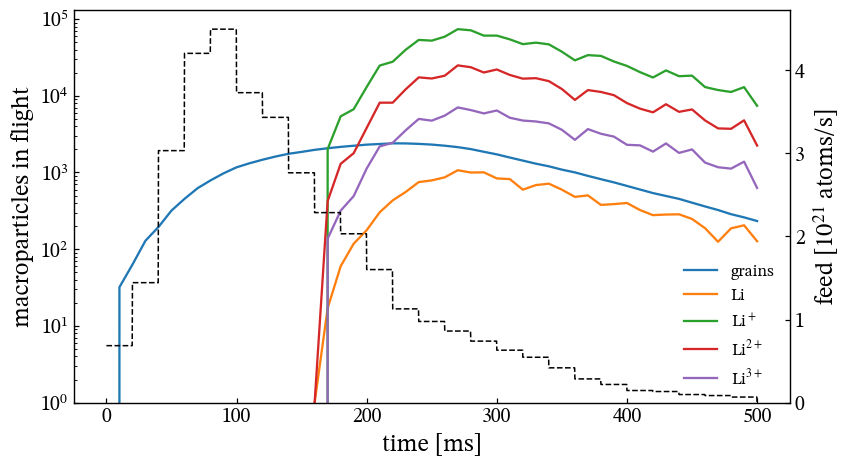

mean over the run, in flight: grains 1176, Li 310, Li^+ 21315, Li^{2+} 7095, Li^{3+} 2052


In [2]:
cols = rows = None
if not LOG.exists():
    print("no log for this run: inventories unavailable (log was overwritten)")
for line in (open(LOG) if LOG.exists() else []):
    t = line.split()
    if t[:2] == ["Step", "CPU"]: cols = t; rows = []; continue
    if cols is not None and len(t) == len(cols) and t[0].isdigit():
        rows.append([float(v) for v in t])
    elif cols is not None and t[:1] == ["Loop"]: break
if cols is None: rows = []
S = {k: np.array([r[i] for r in rows]) for i, k in enumerate(cols)} if cols else {}
if S:
  t_ms = S["Step"] * DT * 1e3
  names = ["grains", "Li", "Li$^+$", "Li$^{2+}$", "Li$^{3+}$"]
  fig, ax = plt.subplots(figsize=(8, 4.5))
  for i, n in enumerate(names, 1):
      if f"c_cnt[{i}]" in S: ax.plot(t_ms, S[f"c_cnt[{i}]"], label=n)
  ax.set(xlabel="time [ms]", ylabel="macroparticles in flight", yscale="log", ylim=(1, None)); ax.legend(loc="lower right")
  ax2 = ax.twinx(); ts = np.arange(0, S["Step"].max() + 1, 100)
  ax2.plot(ts * DT * 1e3, [feed(t) / 1e21 for t in ts], "k--", lw=1); ax2.set_ylabel(r"feed [$10^{21}$ atoms/s]"); ax2.set_ylim(0, None)
  if not PULSE: ax.axvspan(STEADY_FROM * DT * 1e3, STEADY_TO * DT * 1e3, color="0.9")
  plt.tight_layout(); plt.show()
  steady = (S["Step"] > STEADY_FROM) & (S["Step"] <= STEADY_TO)
  print(("mean over the run" if PULSE else "steady") + ", in flight: " + ", ".join(f"{n.replace('$', '')} {S[f'c_cnt[{i}]'][steady].mean():.0f}"
                                         for i, n in enumerate(names, 1) if f"c_cnt[{i}]" in S))

## Landing map

Triangle ids follow `make_geometry.py`: 2-D segment k owns ids `2*NPHI*k+1 .. 2*NPHI*(k+1)`,
strip j the pair `2*NPHI*k + 2*j + 1, +2`, so the wall is a regular (segment, strip) lattice.
Per quad: deposition and grain landing rates = sum of flux x area over its two triangles.
Constant feed: rates averaged over the steady windows [atoms/s]. Pulse: rates x 20 ms summed
over all windows = atoms deposited during the run, compared with the Li injected.

In [3]:
def load_landing(path):
    m = pv.read(path)
    order = np.argsort(np.asarray(m["id"]))
    ids = np.asarray(m["id"])[order]
    assert ids[0] == 1 and ids[-1] == 2 * NPHI * NSEG
    area = np.asarray(m["v_area"])[order]                          # m^2
    li_rate = np.asarray(m["v_Li0_flux"])[order] * area            # atoms/s
    gr_rate = np.asarray(m["v_grain_flux"])[order] * area          # grains/s
    k = (ids - 1) // (2 * NPHI); j = ((ids - 1) % (2 * NPHI)) // 2
    def quad(v):
        a = np.zeros((NSEG, NPHI)); np.add.at(a, (k, j), v); return a
    ions = {k: quad(np.asarray(m[f"v_{k}_flux"])[order] * area) for k in ("Li1", "Li2", "Li3") if f"v_{k}_flux" in m.cell_data}
    return dict(area=quad(area), li_rate=quad(li_rate), grain_rate=quad(gr_rate), **ions)

files = sorted(glob.glob(str(OUT / "landing.*.vtu")), key=lambda p: int(re.findall(r"\d+", p)[-1]))
steps = np.array([int(re.findall(r"\d+", p)[-1]) for p in files])
use = [f for f, s in zip(files, steps) if STEADY_FROM < s <= STEADY_TO]        # file <step> = END of its window
L = [load_landing(f) for f in use]
AREA = L[0]["area"]
if PULSE:                                      # atoms over the run = sum of window-mean rates x window length
    agg = lambda key: np.sum([d[key] for d in L], axis=0) * NWIN * DT
    REF = sum((min(b, steps[-1]) - a) * v for a, b, v in BLOCKS if a < steps[-1]) * ATOMS_PER_MARKER * DT
    print(f"{len(use)} windows integrated over {steps[-1] * DT * 1e3:.0f} ms; Li injected {REF:.3e} atoms")
else:
    agg = lambda key: np.mean([d[key] for d in L], axis=0)
    REF = FEED
    print(f"{len(files)} windows, averaging {len(use)} in ({STEADY_FROM}, {STEADY_TO}]")
LI, GR = agg("li_rate"), agg("grain_rate")     # per quad: atoms (grains) [pulse] or atoms/s [constant]
ION = {k: agg(k) for k in ("Li1", "Li2", "Li3") if k in L[0]}
li_wall = LI.sum(); gr_wall = GR.sum()
gunit = "grains" if PULSE else "grains/s"
print(f"Li atoms to wall {li_wall:.3e} {UNIT}  {pct(li_wall)}")
for k, lab in (("Li1", "Li+"), ("Li2", "Li2+"), ("Li3", "Li3+")):
    if k in ION: print(f"{lab} to wall {ION[k].sum():.3e} {UNIT}  {pct(ION[k].sum())}")
GRAIN_REF = REF / ATOMS_PER_GRAIN
print(f"grains to wall {gr_wall:.3e} {gunit} = {100*gr_wall/GRAIN_REF:.0f}% of the grains injected (grains, not mass)")

26 windows integrated over 500 ms; Li injected 7.207e+20 atoms
Li atoms to wall 7.057e+18 atoms  1.0% of injected Li
Li+ to wall 1.277e+20 atoms  17.7% of injected Li
Li2+ to wall 1.375e+20 atoms  19.1% of injected Li
Li3+ to wall 7.566e+19 atoms  10.5% of injected Li
grains to wall 1.888e+05 grains = 79% of the grains injected (grains, not mass)


## Poloidal and toroidal deposition profiles

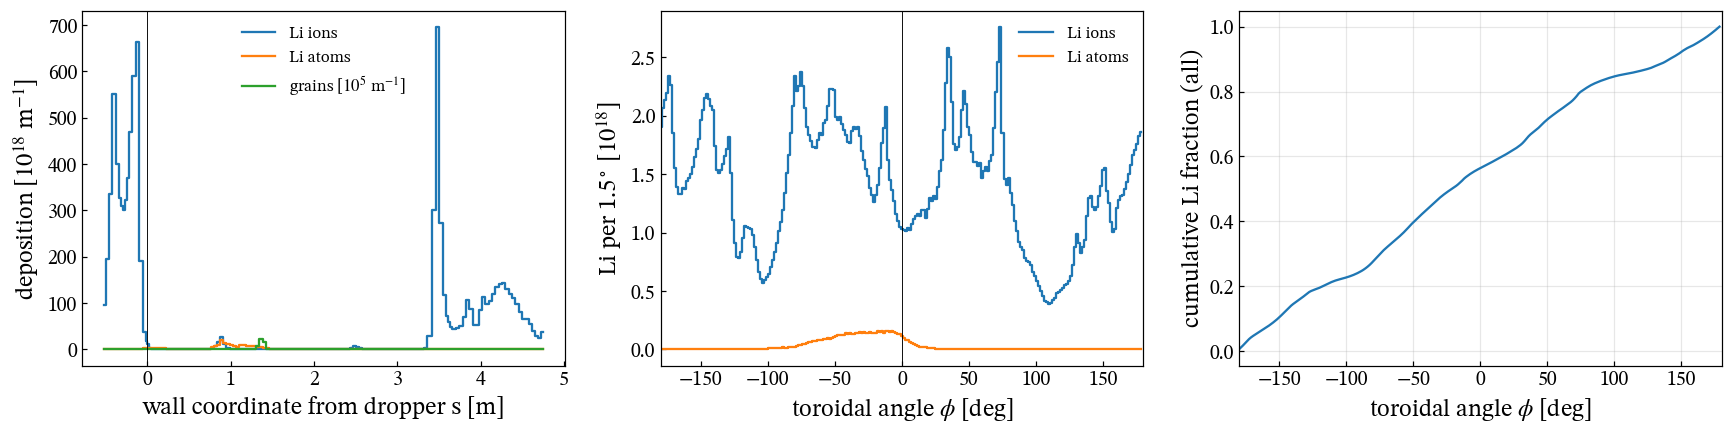

all Li (ions + atoms) to wall 3.479e+20 atoms  48.3% of injected Li
Li lands at phi = -12.8 deg (mean), spatial spread sd 100.9 deg, 90% between -168 and 162 deg
  s = +3.484 m  (R=0.433, Z=-0.764)  7.3% of the Li
  s = -0.118 m  (R=0.433, Z=+0.764)  6.9% of the Li
  s = -0.156 m  (R=0.412, Z=+0.732)  6.8% of the Li
  s = -0.396 m  (R=0.273, Z=+0.537)  6.3% of the Li
  s = -0.196 m  (R=0.389, Z=+0.700)  5.4% of the Li


In [4]:
LION = sum(ION.values()) if ION else np.zeros_like(LI)   # Li+ + Li2+ + Li3+ per quad
LTOT = LI + LION                               # all lithium to the wall
pol, ipol, gpol = LTOT.sum(axis=1) / seg_len, LION.sum(axis=1) / seg_len, GR.sum(axis=1) / seg_len
npol = LI.sum(axis=1) / seg_len
tor, itor, ntor = LTOT.sum(axis=0), LION.sum(axis=0), LI.sum(axis=0)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].step(s_mid_d, ipol / 1e18, where="mid", label="Li ions"); ax[0].step(s_mid_d, npol / 1e18, where="mid", label="Li atoms")
RS = "" if PULSE else " s$^{-1}$"
ax[0].step(s_mid_d, gpol / 1e5, where="mid", label=f"grains [$10^5${RS} m$^{{-1}}$]")
ax[0].set(xlabel="wall coordinate from dropper s [m]", ylabel=f"deposition [$10^{{18}}${RS} m$^{{-1}}$]"); ax[0].legend(); ax[0].axvline(0, c="k", lw=0.6)
ax[1].step(phi_c, itor / 1e18, where="mid", label="Li ions"); ax[1].step(phi_c, ntor / 1e18, where="mid", label="Li atoms")
ax[1].set(xlabel=r"toroidal angle $\phi$ [deg]", ylabel=rf"Li per 1.5$^\circ$ [$10^{{18}}${RS}]", xlim=(-180, 180)); ax[1].axvline(0, c="k", lw=0.6); ax[1].legend()
ax[2].plot(phi_c, np.cumsum(tor) / tor.sum()); ax[2].set(xlabel=r"toroidal angle $\phi$ [deg]", ylabel="cumulative Li fraction (all)", xlim=(-180, 180)); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()
w = tor / tor.sum() if tor.sum() > 0 else np.full_like(tor, np.nan)
phi_mean = (w * phi_c).sum(); phi_sd = np.sqrt((w * (phi_c - phi_mean) ** 2).sum())
p5, p95 = np.interp([0.05, 0.95], np.cumsum(w), phi_c) if tor.sum() > 0 else (np.nan, np.nan)
print(f"all Li (ions + atoms) to wall {LTOT.sum():.3e} {UNIT}  {pct(LTOT.sum())}")
print(f"Li lands at phi = {phi_mean:.1f} deg (mean), spatial spread sd {phi_sd:.1f} deg, 90% between {p5:.0f} and {p95:.0f} deg")
top = np.argsort(pol)[::-1][:5]
for k in top:
    print(f"  s = {s_mid_d[k]:+.3f} m  (R={seg_mid[k,0]:.3f}, Z={seg_mid[k,1]:+.3f})  {100*LTOT[k].sum()/LTOT.sum():.1f}% of the Li")

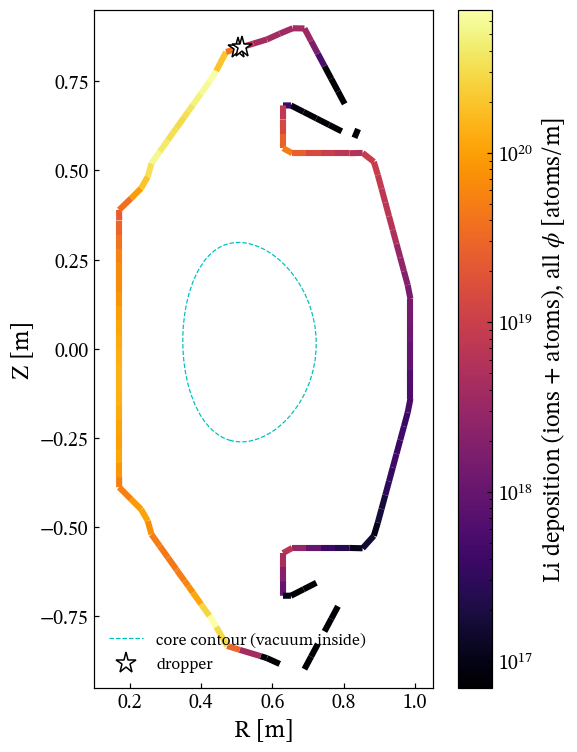

In [5]:
# poloidal view: the 2-D wall coloured by its toroidally integrated Li deposition (ions + atoms)
from matplotlib.collections import LineCollection
segs = np.stack([WALL, np.roll(WALL, -1, axis=0)], axis=1)
fig, ax = plt.subplots(figsize=(6, 8))
lc = LineCollection(segs, cmap="inferno", norm=LogNorm(vmin=max(pol[pol > 0].min(), pol.max() * 1e-4), vmax=pol.max()) if (pol > 0).any() else None, linewidths=4)
lc.set_array(np.where(pol > 0, pol, np.nan)); ax.add_collection(lc)
ax.plot(*np.vstack([CORE, CORE[:1]]).T, "c--", lw=0.8, label="core contour (vacuum inside)")
ax.plot(seg_mid[drop_k, 0], seg_mid[drop_k, 1], "w*", ms=14, mec="k", label="dropper")
fig.colorbar(lc, ax=ax, label=r"Li deposition (ions + atoms), all $\phi$ [" + UNIT + "/m]")
ax.set(xlabel="R [m]", ylabel="Z [m]", aspect="equal", xlim=(0.1, 1.05), ylim=(-0.95, 0.95)); ax.legend(loc="lower left")
plt.show()

## The plume: last particle snapshot

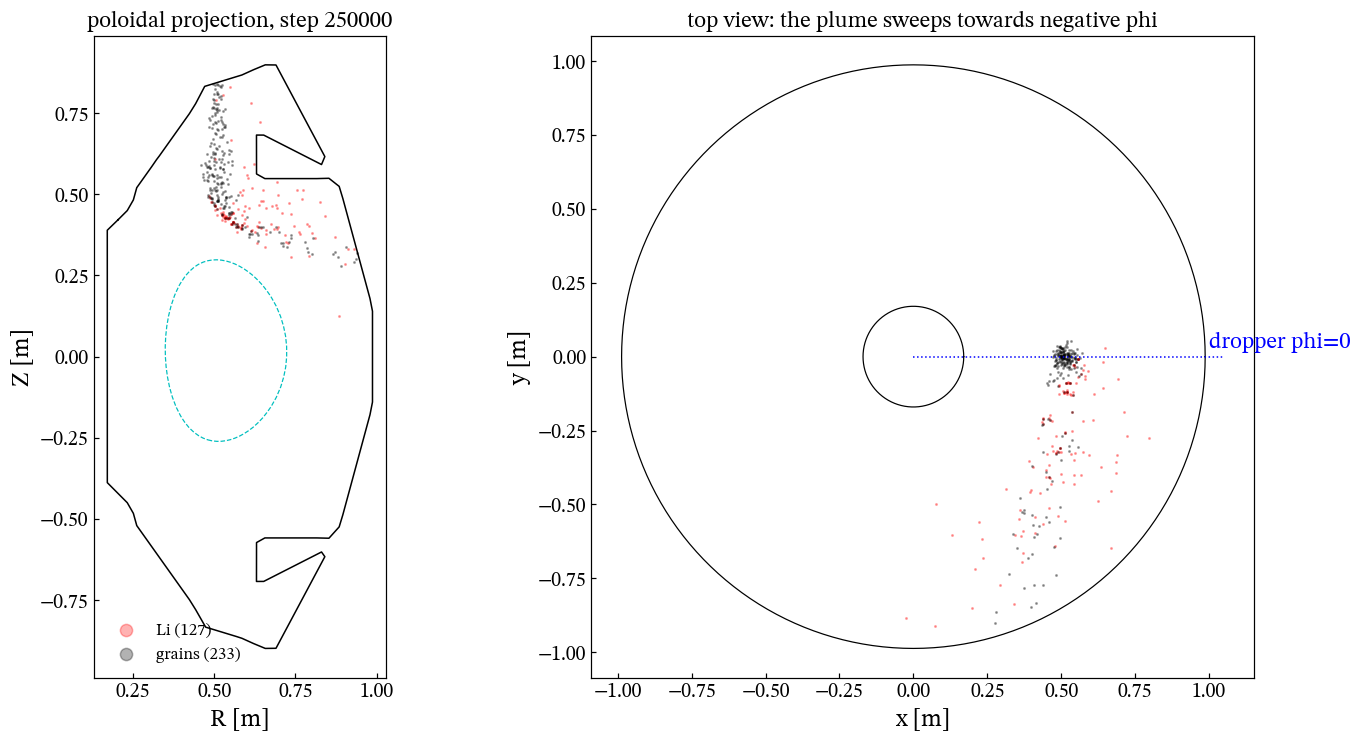

In [6]:
sfiles = sorted(glob.glob(str(OUT / "state.*.vtu")), key=lambda p: int(re.findall(r"\d+", p)[-1]))
m = pv.read(sfiles[-1]); P = np.asarray(m.points); typ = np.asarray(m["type"])
g, li = P[typ == 1], P[typ == 2]
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].plot(*np.vstack([WALL, WALL[:1]]).T, "k-", lw=1); ax[0].plot(*np.vstack([CORE, CORE[:1]]).T, "c--", lw=0.8)
ax[0].scatter(np.hypot(li[:, 0], li[:, 1]), li[:, 2], s=1, c="r", alpha=0.3, label=f"Li ({len(li)})")
ax[0].scatter(np.hypot(g[:, 0], g[:, 1]), g[:, 2], s=1, c="k", alpha=0.3, label=f"grains ({len(g)})")
ax[0].set(xlabel="R [m]", ylabel="Z [m]", aspect="equal", title=f"poloidal projection, step {steps[-1]}"); ax[0].legend(markerscale=8)
th = np.linspace(0, 2 * np.pi, 361)
for r in (WALL[:, 0].min(), WALL[:, 0].max()): ax[1].plot(r * np.cos(th), r * np.sin(th), "k-", lw=0.8)
ax[1].scatter(li[:, 0], li[:, 1], s=1, c="r", alpha=0.3); ax[1].scatter(g[:, 0], g[:, 1], s=1, c="k", alpha=0.3)
ax[1].plot([0, 1.05], [0, 0], "b:", lw=1); ax[1].text(1.0, 0.03, "dropper phi=0", color="b")
ax[1].set(xlabel="x [m]", ylabel="y [m]", aspect="equal", title="top view: the plume sweeps towards negative phi")
plt.tight_layout(); plt.show()

## 2-D (R, Z) distributions, toroidally averaged

Marker positions from the `state.*.vtu` snapshots (steady window, or the whole pulse), binned on
1.5 cm (R, Z) bins: density = markers x weight / (2 pi R dR dZ) / snapshots
(fnum atoms per Li or Li-ion marker, nweight real grains per grain marker).

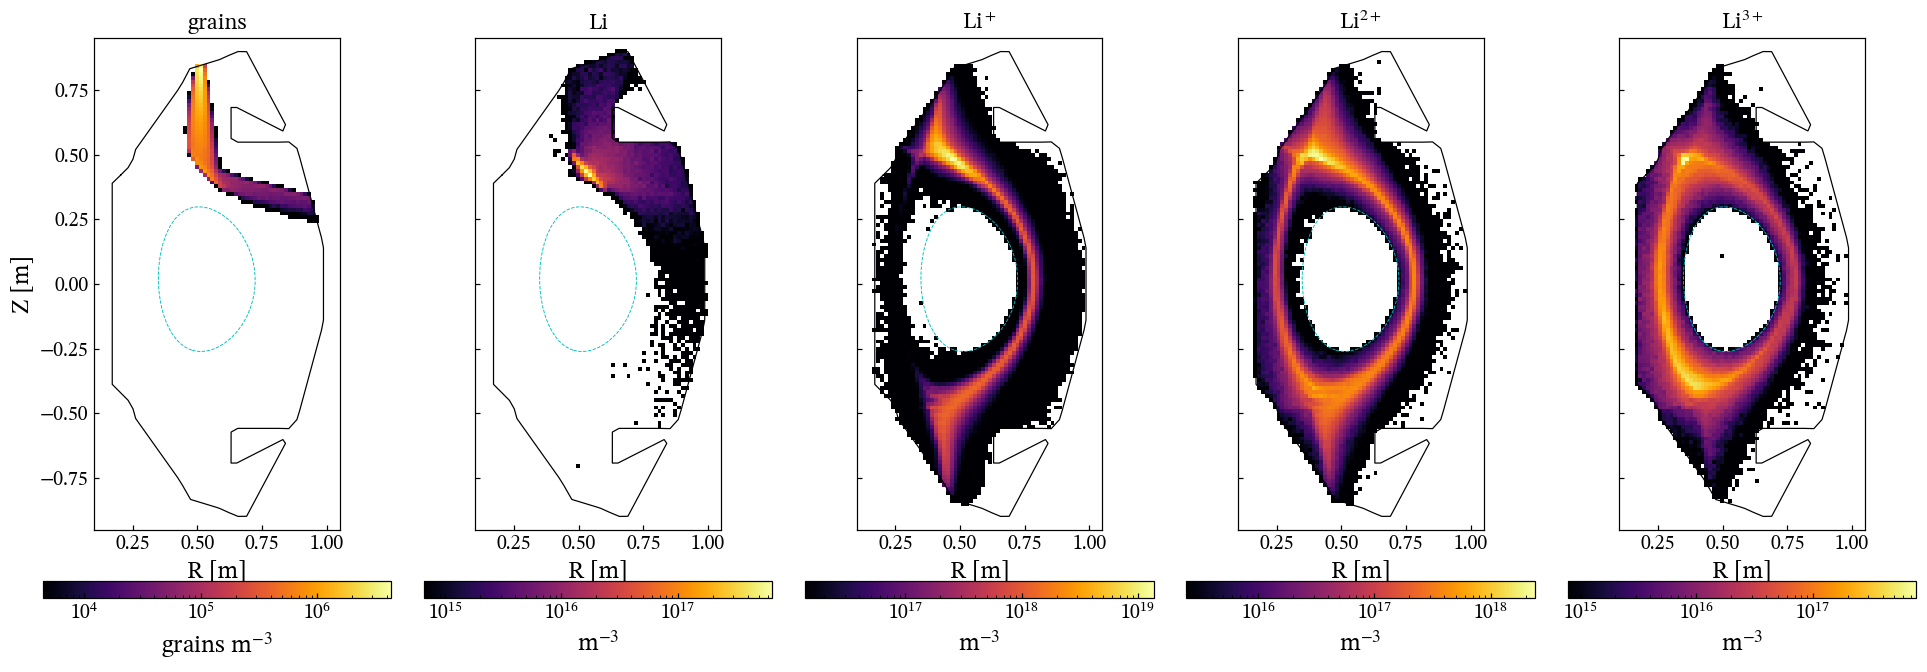

averaged 251 snapshots, steps 0..250000


In [7]:
sfiles = sorted(glob.glob(str(OUT / "state.*.vtu")), key=lambda p: int(re.findall(r"\d+", p)[-1]))
suse = [f for f in sfiles if STEADY_FROM < int(re.findall(r"\d+", f)[-1]) <= STEADY_TO] or sfiles[-1:]
names = ["grains", "Li", "Li$^+$", "Li$^{2+}$", "Li$^{3+}$"]
weight = [NWEIGHT, FNUM, FNUM, FNUM, FNUM]          # real grains / atoms per marker
units = ["grains m$^{-3}$"] + ["m$^{-3}$"] * 4
dR = dZ = 0.015
rb = np.arange(0.1, 1.05 + dR, dR); zb = np.arange(-0.95, 0.95 + dZ, dZ)
ring = 2 * np.pi * 0.5 * (rb[:-1] + rb[1:])[:, None] * dR * dZ
NB = np.zeros((5, len(rb) - 1, len(zb) - 1))
for f in suse:
    m = pv.read(f); P = np.asarray(m.points); typ = np.asarray(m["type"]); R = np.hypot(P[:, 0], P[:, 1])
    for t in range(1, 6):
        NB[t - 1] += np.histogram2d(R[typ == t], P[typ == t, 2], bins=[rb, zb])[0]
NB *= np.array(weight)[:, None, None] / ring / len(suse)
show = [t for t in range(5) if NB[t].any()]
fig, ax = plt.subplots(1, len(show), figsize=(3.6 * len(show), 6.5), sharey=True)
for a, t in zip(np.atleast_1d(ax), show):
    H = np.where(NB[t] > 0, NB[t], np.nan)
    im = a.pcolormesh(rb, zb, H.T, norm=LogNorm(vmin=np.nanmax(H) * 1e-3, vmax=np.nanmax(H)), cmap="inferno")
    a.plot(*np.vstack([WALL, WALL[:1]]).T, "k-", lw=0.8); a.plot(*np.vstack([CORE, CORE[:1]]).T, "c--", lw=0.6)
    a.set(xlabel="R [m]", aspect="equal", title=names[t], xlim=(0.1, 1.05), ylim=(-0.95, 0.95))
    fig.colorbar(im, ax=a, orientation="horizontal", pad=0.08, label=units[t])
np.atleast_1d(ax)[0].set_ylabel("Z [m]")
plt.tight_layout(); plt.show()
print(f"averaged {len(suse)} snapshots, steps {int(re.findall(r'\d+', suse[0])[-1])}..{int(re.findall(r'\d+', suse[-1])[-1])}")

## Synthetic line-integrated Li I / Li II signals

Brightness along each chord, B(t) = (1/4pi) sum over markers within RC of the chord of
weight x n_e x PEC(Te, ne) / (pi RC^2)  [photons m^-2 s^-1 sr^-1], from the particle snapshots
(every ndump steps). Li I 670.8 nm = Li excitation + Li+ recombination; Li II 548.5 nm =
Li+ excitation + Li2+ recombination (open-ADAS pec96 in `database/processes.h5`). Te, ne at each
marker from the plasma file. Chords: the ST40 Avantes lines of sight (#6/#8 midplane through the IPD
sector, #7 at machine phi 135 deg, 65 deg from the IPD, looking up at the upper divertor), read off the diagnostic
layout; machine phi counter-clockwise = sim +phi is assumed. Measured traces: shot 14449 Avantes ch6/7/8,
`../input/14449_avantes_lines.csv`.

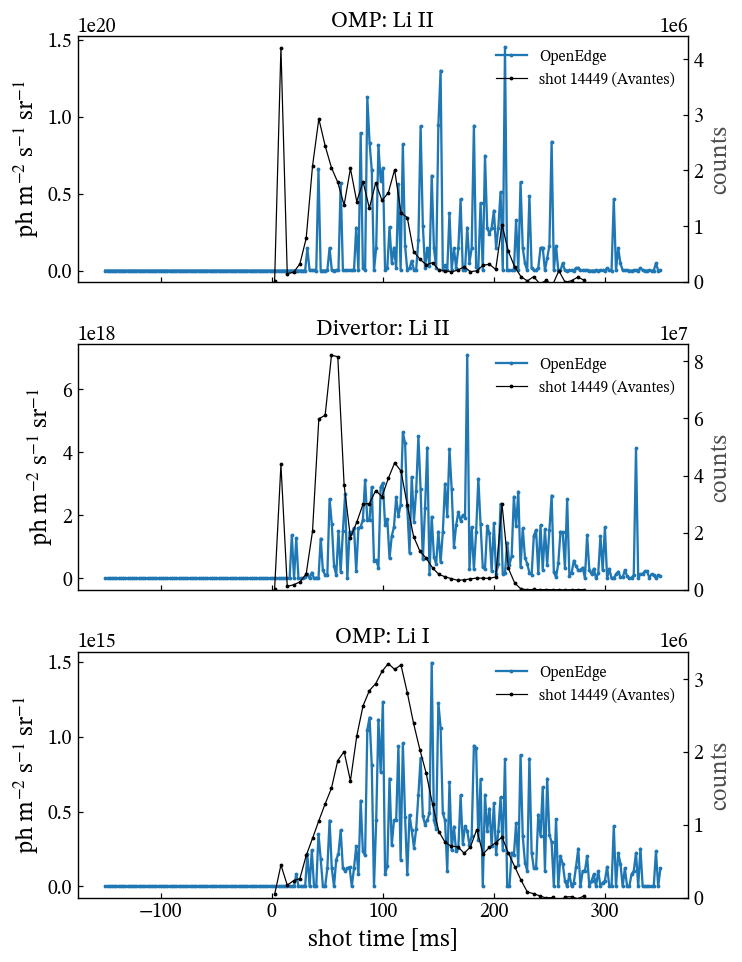

OMP       Li II  peak 1.453e+20 at 210 ms
Divertor  Li II  peak 7.096e+18 at 176 ms
OMP       Li I   peak 1.493e+15 at 144 ms


In [8]:
import h5py
from matplotlib.tri import Triangulation
from scipy.interpolate import RegularGridInterpolator
def xyz(R, phi_deg, Z):
    return np.array([R * np.cos(np.radians(phi_deg)), R * np.sin(np.radians(phi_deg)), Z])
PHI_IPD = 70.0                                       # machine toroidal angle of the IPD = sim phi 0
# Avantes lines of sight from the ST40 diagnostic layout (E. Tinacba, Oct 27 2026), read by eye (+-3 cm, +-3 deg):
# (R, machine phi, Z) at both ends; assumes machine phi (counter-clockwise from above) = sim +phi
CHORDS = {
    "OMP":      (xyz(1.00, 68.0 - PHI_IPD, 0.00), xyz(0.15, 72.0 - PHI_IPD, 0.00)),    # #6 Li II, #8 Li I ("LINES", port S2)
    "Divertor": (xyz(1.00, 135.0 - PHI_IPD, -0.22), xyz(0.22, 135.0 - PHI_IPD, 1.17)), # #7 Li II ("DIV SRVY"), phi 135 deg (Erin)
}
RC = 0.02                                            # chord radius [m]
_m = re.search(r"sim t = 0 is shot (-?[\d.]+) ms", open(CASE / "input/srate_3d.deck").read())
T0_MS = (float(_m.group(1)) if _m else 40.0) if PULSE else 0.0   # shot time of sim t = 0 (make_srate.py)

ROOT = CASE.parents[5]                               # repository root
db = h5py.File(ROOT / "database/processes.h5", "r")
def pec(key):
    g = db[f"volume/pec/li/96/{key}"]
    f = RegularGridInterpolator((g["temperature"][()], g["density"][()]), g["coefficient"][()],
                                bounds_error=False, fill_value=None)
    lo, hi = (g["temperature"][0], g["density"][0]), (g["temperature"][-1], g["density"][-1])
    return lambda te, ne: 10 ** f(np.column_stack([np.clip(np.log10(te), lo[0], hi[0]),
                                                   np.clip(np.log10(ne), lo[1], hi[1])])) * 1e-6   # m^3/s
LINES = {"Li I":  [(2, pec("li0_6710_pec")), (3, pec("li0_6710_recom_pec"))],   # (marker type, PEC)
         "Li II": [(3, pec("li1_5486_pec")), (4, pec("li1_5486_recom_pec"))]}
pf = h5py.File(CASE / re.search(r"variable plasma\s+index\s+(\S+)", deck).group(1), "r")["mesh"]
cidx = pf["cell_index"][()]
tf = Triangulation(pf["vtx_r"][()], pf["vtx_z"][()], pf["triangles"][()]).get_trifinder()
TE, NE = pf["temp_e"][()], pf["dens_e"][()]

def near_chord(P, a, b):
    d = b - a; L = np.linalg.norm(d); u = d / L
    s = (P - a) @ u
    return (s >= 0) & (s <= L) & (np.linalg.norm(P - a - np.outer(s, u), axis=1) < RC)

tms, SIG = [], {(ch, ln): [] for ch in CHORDS for ln in LINES}
for f in sfiles:
    m = pv.read(f); P = np.asarray(m.points); typ = np.asarray(m["type"])
    k = tf(np.hypot(P[:, 0], P[:, 1]), P[:, 2]); inside = (k >= 0) & (cidx[np.maximum(k, 0)] >= 0)
    te = np.where(inside, TE[cidx[np.maximum(k, 0)]], 0.0); ne = np.where(inside, NE[cidx[np.maximum(k, 0)]], 0.0)
    tms.append(int(re.findall(r"\d+", f)[-1]) * DT * 1e3 + T0_MS)
    for ch, (a, b) in CHORDS.items():
        sel = near_chord(P, a, b) & inside & (ne > 0)
        for ln, terms in LINES.items():
            tot = 0.0
            for t, fn in terms:
                q = sel & (typ == t)
                if q.any(): tot += (FNUM * ne[q] * fn(te[q], ne[q])).sum()
            SIG[(ch, ln)].append(tot / (4 * np.pi) / (np.pi * RC**2))
tms = np.array(tms)
panels = [("OMP", "Li II"), ("Divertor", "Li II"), ("OMP", "Li I")]
MEAS = {("OMP", "Li II"): "omp_li2", ("Divertor", "Li II"): "div_li2", ("OMP", "Li I"): "omp_li1"}
mfile = CASE.parent / "input/14449_avantes_lines.csv"          # measured, shot 14449 (Avantes ch6/7/8)
meas = np.genfromtxt(mfile, delimiter=",", names=True, skip_header=1) if mfile.exists() else None
fig, ax = plt.subplots(3, 1, figsize=(7, 9), sharex=True)
for a, key in zip(ax, panels):
    a.plot(tms, np.array(SIG[key]), ".-", ms=3, label="OpenEdge")
    a.set(title=f"{key[0]}: {key[1]}", ylabel=r"ph m$^{-2}$ s$^{-1}$ sr$^{-1}$")
    if meas is not None:
        b = a.twinx(); b.plot(meas["time_ms"], meas[MEAS[key]], "k.-", ms=3, lw=0.8, label="shot 14449 (Avantes)")
        b.set_ylabel("counts", color="0.3"); b.set_ylim(0, None)
        a.legend(handles=a.get_lines() + b.get_lines(), loc="upper right", fontsize=10)
ax[-1].set_xlabel("shot time [ms]")
plt.tight_layout(); plt.show()
for key in panels:
    v = np.array(SIG[key]); print(f"{key[0]:9s} {key[1]:6s} peak {v.max():.3e} at {tms[v.argmax()]:.0f} ms")

## Summary

- Most of the ablated lithium is ionized; the wall load is dominated by Li ions (Li+, Li2+, Li3+), with
  neutral Li atoms a small fraction. Totals are printed above as % of the Li fed.
- Grains reach the wall partly ablated: the grain wall fraction counts grains, not lithium mass.
- The ions fill a scrape-off-layer ring around the core; neutral Li stays close to the grain path, which
  sweeps towards negative phi as the grains pick up toroidal velocity from ion drag.